# Topic 5: Baryon acoustic oscillations: Part 2
**Group members: Evan Balwani, Niko Jamison, Logan Lajiness**  
**Group size: 3 people**  
**Extension(s) chosen: both**  

**Work plan (who owns which module; see Common Instructions section 4):**  
- Module A, Physics: Niko Jamison
- Module B, Code: Evan Balwani, Logan Lajiness
- Module C, Validation and figures: Evan Balwani, Logan Lajiness
- Reviewers:  


## Summary

Within the project, we analyzed how baryon acoustic oscillations (BAO) were applied to measure cosmic distances and the expansion of the universe, making it a standard ruler for cosmologists. Firstly, we derived how sound waves in the early photon-baryon plasma created a fixed comoving scale, and how this appears and relates to angular and radial separations. Furthermore, we derived the isotropic distance, the relationship between the galaxy correlation function, and the power spectrum using a 3D Fourier transform, and how a Gaussian bump creates oscillation or wiggles in the power spectrum.  

 

Utilizing python, we calculated cosmological distance, angular separations, and redshift intervals at various redshifts and matter densities. Furthermore, we modeled the correlation function, analyzed the power spectrum quantitatively, and then compared our results with approximation and our reference values.  

 

In summation, the BAO provides cosmologists with a tool that is a measurable distance scale to help analyze the universe's expansion and help constrain cosmological parameters.  

In [2]:
# Setup: imports, constants, seed, data path
import numpy as np
import scipy
import matplotlib.pyplot as plt
# import pandas as pd

rng = np.random.default_rng(5682)   # fixed seed, for reproducibility
DATA = './data/'                    # read files from here; do not use absolute paths

# Physical constants (state units!):
c = 299792.458 # km/s
hubble_const = 67.36 # km/s/Mpc
omega_m = 0.3138 # unitless
omega_lambda = 1 - omega_m # unitless
r_d = 147.09 # Mpc

h = 0.6736 # unitless
r_d_h = 99.1 # Mpc/h

# Constants for Code 2 
A = .01               # unitless
gamma = 1.8           # unitless
B = .002              # unitless
r_bao = 100           # Mpc
sigma = 10.0          # Mpc

r_taper = 300         # Mpc
r_min = .01           # Mpc
r_max = 1000         # Mpc


## Physics and derivations

### Physics 1: Origin of the ruler

When photons and baryons were coupled in the early universe, radiation pressure from photons caused over and under densities, or sound waves, of baryonic matter. When photons and baryons decoupled at the drag epoch ($z_d \approx 1060$), the radiation pressure ceased, and these sound waves were frozen leaving a spherical shell around the original overdensity. After the drag epoch, the universe continued to expand, expanding the physical seperation of the sound waves, but the comoving seperation ($r_d$) remained approximately constant. 

### Physics 2: Observable sizes

The BAO scale $r_d$ is a comoving distance. For a transverse measurement, the angular separation is related to the comoving transverse distance $D_M(z)$ using the small-angle approximation.

$$\tan\left(\frac{\Delta\theta}{2}\right)=\frac{r_d}{2D_M(z)}$$

For small angles, $\tan(\Delta\theta/2)\approx\Delta\theta/2$, giving

$$\Delta\theta=\frac{r_d}{D_M(z)}$$

We can also express this using the angular diameter distance $d_A(z)$. The proper size of the BAO scale at redshift $z$ is $a(z)r_d$, where $a(z)=1/(1+z)$.

$$\Delta\theta=\frac{a(z)r_d}{d_A(z)}$$

Substituting the scale factor gives

$$\Delta\theta=\frac{r_d}{(1+z)d_A(z)}$$

Therefore,

$$\boxed{\Delta\theta=\frac{r_d}{D_M(z)}=\frac{r_d}{(1+z)d_A(z)}}$$

For the radial direction, the comoving distance is

$$D_C(z)=c\int_0^z\frac{dz'}{H(z')}$$

For a small redshift interval $\Delta z$,

$$\Delta D_C\approx\frac{c}{H(z)}\Delta z$$

Since the BAO scale is $r_d$, we set $\Delta D_C=r_d$:

$$r_d\approx\frac{c}{H(z)}\Delta z$$

Rearranging gives

$$\boxed{\Delta z\approx\frac{H(z)r_d}{c}}$$

Finally, defining $D_H(z)=c/H(z)$, the dimensionless distance combinations are

$$\boxed{\frac{D_M(z)}{r_d}\quad\text{and}\quad\frac{D_H(z)}{r_d}}$$


### Physics 3: Isotropic distance $D_V$

As you average the correlation function over all three directions, you have two transverse directions and one radial direction. The transverse directions both have a factor of $\alpha_\perp$, and the radial direction has a factor of $\alpha_\parallel$. Combining these three directions gives a volume dilation of $\alpha_\perp^2\alpha_\parallel$. Due to the 3D volume, you take the cube root to get a distance scale.

$$
\alpha_{\mathrm{eff}} = (\alpha_\perp^2\alpha_\parallel)^{1/3}
$$

The two transverse directions depend on $D_M(z)$, and the radial direction depends on the Hubble distance $c/H(z)$. Combining these gives an effective volume proportional to $D_M^2(z)c/H(z)$. Taking the cube root gives the isotropic distance scale:

$$
\boxed{D_V(z) = \left[zD_M^2(z)\frac{c}{H(z)}\right]^{1/3}}
$$


### Physics 4: From xi(r) to P(k)



We start with the three-dimensional Fourier transform: 

 

$$ 

P(\mathbf{k})=\int \xi(\mathbf{r})e^{-i\mathbf{k}\cdot\mathbf{r}}\,d^3r 

$$ 

 

The wavenumber is defined as 

 

$$ 

k=\frac{2\pi}{\lambda} 

$$ 

 

Converting to spherical coordinates, the volume element is 

 

$$ 

d^3r=r^2\sin\theta\,dr\,d\theta\,d\phi 

$$ 

 

Using the polar axis along $\mathbf{k}$ gives 

 

$$ 

\mathbf{k}\cdot\mathbf{r}=kr\cos\theta 

$$ 

 

Therefore, 

 

$$ 

P(k)=\int_0^\infty\int_0^\pi\int_0^{2\pi} 

\xi(r)e^{-ikr\cos\theta}r^2\sin\theta 

\,d\phi\,d\theta\,dr 

$$ 

 

Integrating over $\phi$: 

 

$$ 

\int_0^{2\pi}d\phi=2\pi 

$$ 

 

This gives 

 

$$ 

P(k)=2\pi\int_0^\infty\xi(r)r^2 

\left[\int_0^\pi e^{-ikr\cos\theta}\sin\theta\,d\theta\right]dr 

$$ 

 

Using the substitution 

 

$$ 

u=\cos\theta,\qquad du=-\sin\theta\,d\theta 

$$ 

 

the angular integral becomes 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

$$ 

 

Integrating gives 

 

$$ 

=\frac{e^{-ikr}-e^{ikr}}{-ikr} 

$$ 

 

Using Euler's identity, 

 

$$ 

e^{ix}-e^{-ix}=2i\sin x 

$$ 

 

we obtain 

 

$$ 

\int_{-1}^{1}e^{-ikru}\,du 

=\frac{2\sin(kr)}{kr} 

$$ 

 

Substituting back: 

 

$$ 

P(k)=2\pi\int_0^\infty 

\xi(r)r^2\frac{2\sin(kr)}{kr}\,dr 

$$ 

 

Therefore, 

 

$$ 

\boxed{P(k)=4\pi\int_0^\infty 

\xi(r)\frac{\sin(kr)}{kr}r^2\,dr} 

$$ 

 

### Inverse Fourier Transform 

 

The inverse transform is 

 

$$ 

\boxed{\xi(r)=\frac{1}{2\pi^2} 

\int_0^\infty P(k)\frac{\sin(kr)}{kr}k^2\,dk} 

$$ 

 

### Why a 1D Fourier Transform Is Incorrect 

 

A one-dimensional Fourier transform is incorrect because the galaxy correlation function describes separations in three-dimensional space. Although the correlation function only depends on the distance $r$, it is still three-dimensional, so we must integrate over all spatial directions. This introduces the spherical volume factor $r^2$ and the angular factor $\sin(kr)/(kr)$, which would be missing in a one-dimensional Fourier transform. 

### Physics 5: Wiggles from a bump



We start with a narrow Gaussian bump in the correlation function: 

 

$$ 

\xi_{\mathrm{bump}}(r)=B\exp\left[-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}\right] 

$$ 

 

where $B$ is the amplitude, $r_{\mathrm{BAO}}$ is the location of the bump, and $\sigma$ is its width. We assume $\sigma \ll r_{\mathrm{BAO}}$. 

 

### Substituting into the Fourier transform 

 

From Physics 4, the three-dimensional Fourier transform is 

 

$$ 

P(k)=4\pi\int_0^\infty \xi(r)\frac{\sin(kr)}{kr}r^2\,dr 

$$ 

 

Substituting the Gaussian bump gives 

 

$$ 

P_{\mathrm{bump}}(k)=4\pi B\int_0^\infty 

e^{-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}} 

\frac{r\sin(kr)}{k}\,dr 

$$ 

 

### Applying the narrow-bump approximation 

 

Since the Gaussian is concentrated near $r=r_{\mathrm{BAO}}$, we approximate the slowly varying factor as 

 

$$ 

\frac{r}{k}\approx\frac{r_{\mathrm{BAO}}}{k} 

$$ 

 

Therefore, 

 

$$ 

P_{\mathrm{bump}}(k)\approx 

\frac{4\pi B r_{\mathrm{BAO}}}{k} 

\int_0^\infty 

e^{-\frac{(r-r_{\mathrm{BAO}})^2}{2\sigma^2}} 

\sin(kr)\,dr 

$$ 

 

Let 

 

$$ 

u=r-r_{\mathrm{BAO}} 

$$ 

 

Because the Gaussian is narrow and centered far from zero, we extend the integration limits to $(-\infty,\infty)$: 

 

$$ 

P_{\mathrm{bump}}(k)\approx 

\frac{4\pi B r_{\mathrm{BAO}}}{k} 

\int_{-\infty}^{\infty} 

e^{-u^2/(2\sigma^2)} 

\sin[k(u+r_{\mathrm{BAO}})]\,du 

$$ 

 
### Evaluating the Gaussian integral 

 

Using the trigonometric identity 

 

$$ 

\sin[k(u+r_{\mathrm{BAO}})] 

= 

\sin(ku)\cos(kr_{\mathrm{BAO}}) 

+ 

\cos(ku)\sin(kr_{\mathrm{BAO}}) 

$$ 

 

The term containing $\sin(ku)$ integrates to zero because it is an odd function multiplied by an even Gaussian. 

 

The remaining integral is 

 

$$ 

\int_{-\infty}^{\infty} 

e^{-u^2/(2\sigma^2)}\cos(ku)\,du 

= 

\sqrt{2\pi}\sigma e^{-k^2\sigma^2/2} 

$$ 

 

Substituting back gives 

 

$$ 

\boxed{ 

P_{\mathrm{bump}}(k)\approx 

4\pi B r_{\mathrm{BAO}}\sqrt{2\pi}\sigma 

\frac{\sin(kr_{\mathrm{BAO}})}{k} 

e^{-k^2\sigma^2/2} 

} 

$$ 

 
### Finding the oscillation period 

 

The oscillations come from the sine factor 

 

$$ 

\sin(kr_{\mathrm{BAO}}) 

$$ 

 

Since the sine function repeats every $2\pi$, 

 

$$ 

\Delta k\,r_{\mathrm{BAO}}=2\pi 

$$ 

 

Rearranging gives 

 

$$ 

\boxed{\Delta k=\frac{2\pi}{r_{\mathrm{BAO}}}} 

$$ 

 

For $r_{\mathrm{BAO}}=100\,h^{-1}\mathrm{Mpc}$, 

 

$$ 

\Delta k=\frac{2\pi}{100\,h^{-1}\mathrm{Mpc}} 

$$ 

 

Therefore, 

 

$$ 

\boxed{\Delta k\approx0.0628\,h\,\mathrm{Mpc}^{-1}} 

$$ 

 
### Explaining the damping 

 

The exponential factor 

 

$$ 

e^{-k^2\sigma^2/2} 

$$ 

 

reduces the amplitude of the oscillations as $k$ increases. 

 

When 

 

$$ 

k\gtrsim\frac{1}{\sigma} 

$$ 

 

the oscillations become increasingly damped. A wider Gaussian bump in real space produces stronger damping at smaller values of $k$. 

 

### Conclusion 

 

A localized Gaussian bump in the galaxy correlation function $\xi(r)$ produces oscillations in the power spectrum $P(k)$. The location of the bump, $r_{\mathrm{BAO}}$, determines the oscillation period $\Delta k=2\pi/r_{\mathrm{BAO}}$, while the width $\sigma$ determines how quickly the oscillations are damped. Nonlinear evolution broadens the real BAO feature, causing additional damping of the oscillations in the power spectrum. 

## Code

### Code 1: H(z), D_M, D_H, D_V; Delta theta and Delta z

In [12]:
# function of Hubble parameter
def H_z(z, hubble_const, omega_m):
    '''
    Calculates the Hubble parameter at a given redshift for a flat model
    Enter your value of z, returns in units of km/s/Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calculating Hubble parameter
    H = hubble_const * np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    return H

# function of comoving distance
def D_M(z, hubble_const, omega_m):
    '''
    Calculates the transverse comoving distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # setting up the integral
    def integral(z):
        return 1 / np.sqrt(omega_m * (1 + z)**3 + omega_lambda)

    # integrating from 0 to z
    integral = scipy.integrate.quad(integral, 0, z)[0]

    # calculating comoving distance in Mpc
    distance = (c / hubble_const) * integral

    return distance

# function of Hubble distance
def D_H(z, hubble_const, omega_m):
    '''
    Calculates the Hubble distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling previous Hubble parameter
    H = H_z(z, hubble_const, omega_m)

    # calculating Hubble distance in Mpc
    distance = c / H

    return distance

# function of volume-averaged distance
def D_V(z, hubble_const, omega_m):
    '''
    Calculates the volume-averaged distance at a given redshift for a flat model
    Enter your value of z, returns in units of Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating volume-averaged distance in Mpc
    distance = (z * hubble * transverse**2) ** (1/3)

    return distance

# function Angular BAO scale in degrees
def delta_theta(z, hubble_const, omega_m, r_d):
    '''
    Calculates the angular BAO scale in degrees
    Enter your value of z, returns in units of degrees
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m
    
    # calling transverse comoving distance
    transverse = D_M(z, hubble_const, omega_m)
    
    # converting angular distance to radians
    theta = r_d / transverse

    # converting radians to degrees
    theta = theta * (180 / np.pi)

    return theta

# function for Radial BAO scale
def delta_z(z, hubble_const, omega_m, r_d):
    '''
    Calculates the radial BAO scale
    Enter your value of z, returns in units of redshift
    '''
     # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # calling Hubble distance
    hubble = D_H(z, hubble_const, omega_m)

    # calculating radial redshift separation
    separation = r_d / hubble

    return separation

### Code 2: xi_model and P_of_k

In [4]:
# Correlation Function
def xi_model(r, A, gamma, B, r_bao, sigma):
    smooth = A * (r / 100.0)**(-gamma)
    bump = B * np.exp(-((r - r_bao) ** 2) / (2*sigma**2))
    return smooth + bump

# Power Spectrum Function 
def P_ofk(xi_func, k, A, gamma, B, r_bao, sigma,
          r_taper, r_min, r_max):
    def _calc_single_k(k_val):
        def integrand(r):
            taper = np.exp(-(r / r_taper) ** 2)
            xi_val = xi_func(r, A, gamma, B, r_bao, sigma)
            return 4.0 * np.pi * xi_val * (np.sin(k_val * r) / (k_val * r)) * (r**2) * taper

        val, _ = scipy.integrate.quad(integrand, r_min, r_max, limit=200)
        return val

    if np.isscalar(k):
        return _calc_single_k(k)
    return np.array([_calc_single_k(kv) for kv in k])

# Smooth background for P_k
def xi_smooth_func(r, A, gamma, B, r_bao, sigma):
    return A * (r / 100.0)**(-gamma)

The taper smooths the graph out at low k's, so that the measurements do not become super sharp, and unphysical.

## Results
*Every plot: labeled axes with units, a legend, and a one- or two-sentence caption.*

### Plot 1: D_M/r_d, D_H/r_d, D_V/r_d vs. z for three Omega_m

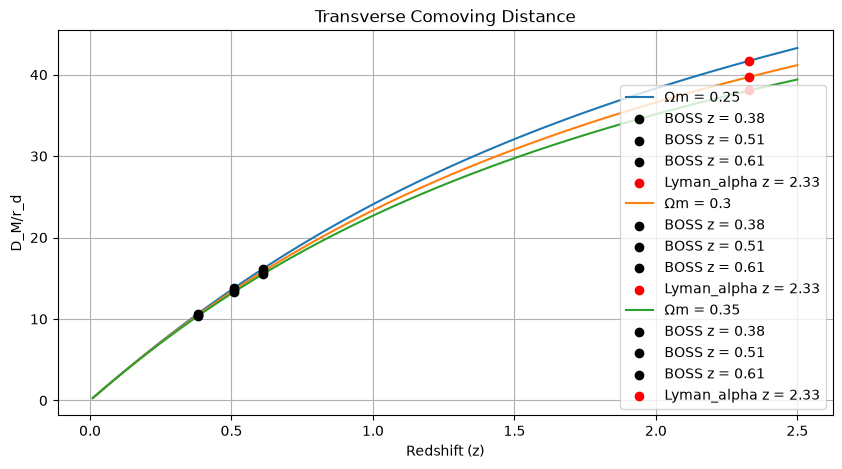

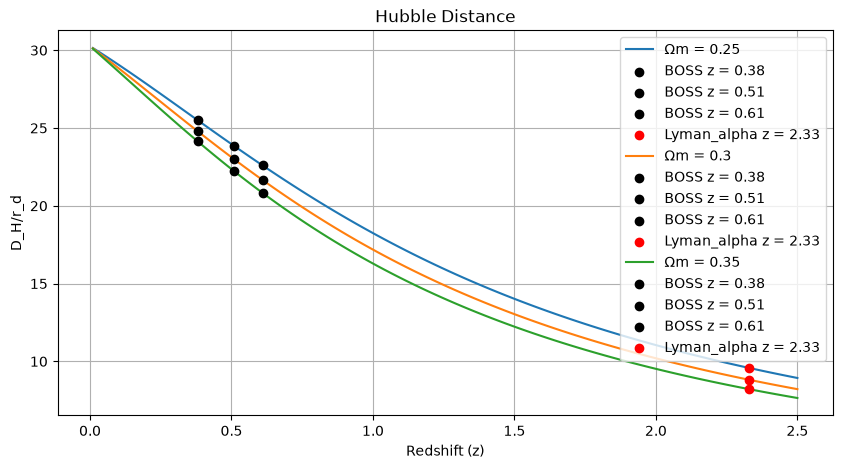

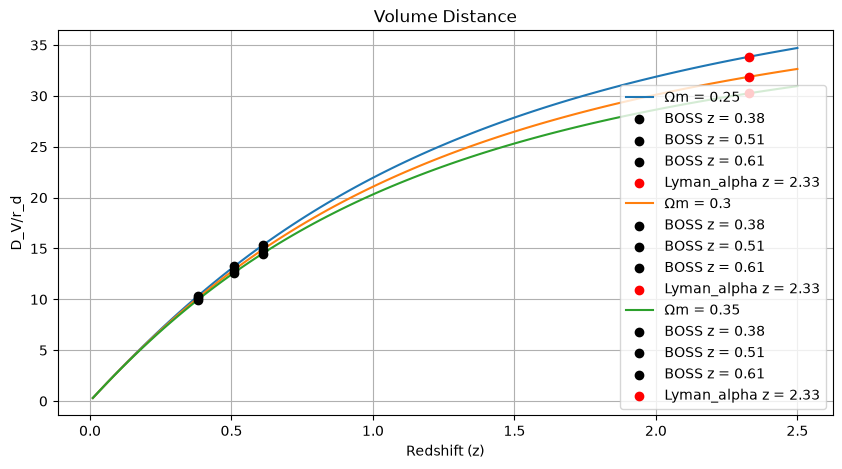

In [17]:
# setting redshift range
z_range = np.linspace(0.01, 2.5, 100)

# setting three matter density values
omega_values = [0.25, 0.30, 0.35]

# setting redshifts markers for BOSS and Lyman-alpha BAO
boss_redshifts = [0.38, 0.51, 0.61]
lyman_alpha_redshift = [2.33]

# plotting D_M vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_M/r_d for each redshift value at each matter density value
for omega_m in omega_values:
    DM_values = [D_M(z, hubble_const, omega_m) / r_d for z in z_range]
    plt.plot(z_range, DM_values, label=f'Ωm = {omega_m}')
    # adding boss markers
    for redshift in boss_redshifts:
        distance = D_M(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
    # adding lyman_alpha markers
    for redshift in lyman_alpha_redshift:
        distance = D_M(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_M/r_d')
plt.title('Transverse Comoving Distance')
plt.grid(True)
plt.legend()

# plotting D_H vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_H/r_d for each redshift value at each matter density value
for omega_m in omega_values:
    DH_values = [D_H(z, hubble_const, omega_m) / r_d for z in z_range]
    plt.plot(z_range, DH_values, label=f'Ωm = {omega_m}')
    # adding boss markers
    for redshift in boss_redshifts:
        distance = D_H(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
    # adding lyman_alpha markers
    for redshift in lyman_alpha_redshift:
        distance = D_H(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_H/r_d')
plt.title('Hubble Distance')
plt.grid(True)
plt.legend()

# plotting D_V vs z for Omega m = 0.25, 0.30, 0.35
plt.figure(figsize=(10, 5))
# calculating D_V/r_d for each redshift value for each matter density value
for omega_m in omega_values:
    DV_values = [D_V(z, hubble_const, omega_m) / r_d for z in z_range]
    plt.plot(z_range, DV_values, label=f'Ωm = {omega_m}')
    # adding boss markers
    for redshift in boss_redshifts:
        distance = D_V(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='black', marker='o', zorder=5, label=f'BOSS z = {redshift}')
    # adding lyman_alpha markers
    for redshift in lyman_alpha_redshift:
        distance = D_V(redshift, hubble_const, omega_m) / r_d
        plt.scatter(redshift, distance, color='red', marker='o', zorder=5, label=f'Lyman_alpha z = {redshift}')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('D_V/r_d')
plt.title('Volume Distance')
plt.grid(True)
plt.legend()

**Caption:** 

The first plot shows the transverse comoving distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS redshifts z=0.38, 0.51, 0.61 and the Lyman-alpha redshift z=2.33.

The second plot shows the hubble distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS and Lyman-alpha BAO redshifts, allowing the distances to be compared across different redshifts.

The third plot shows the volume-averaged distance divided by the sound horizon against redshift for three different values of the matter density parameter, Omega_m. The black markers show the reference cosmology at the BOSS and Lyman-alpha BAO redshifts, illustrating how the volume-averaged distance changes with redshift.


### Plot 2: Delta theta(z) and Delta z(z)

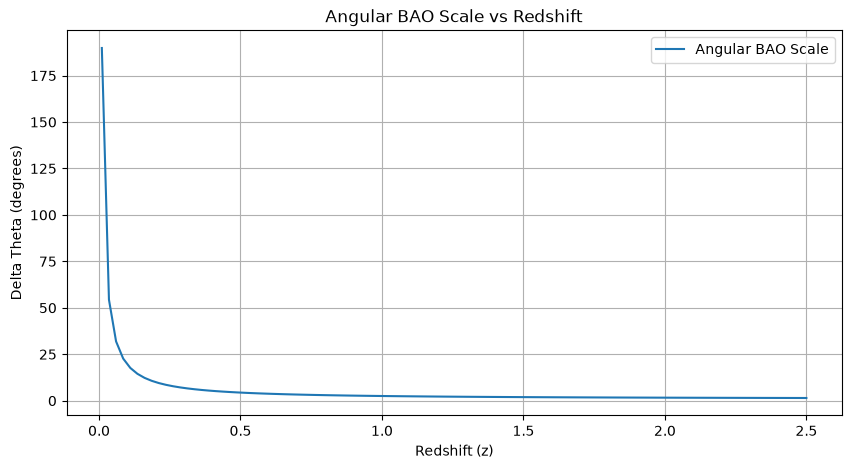

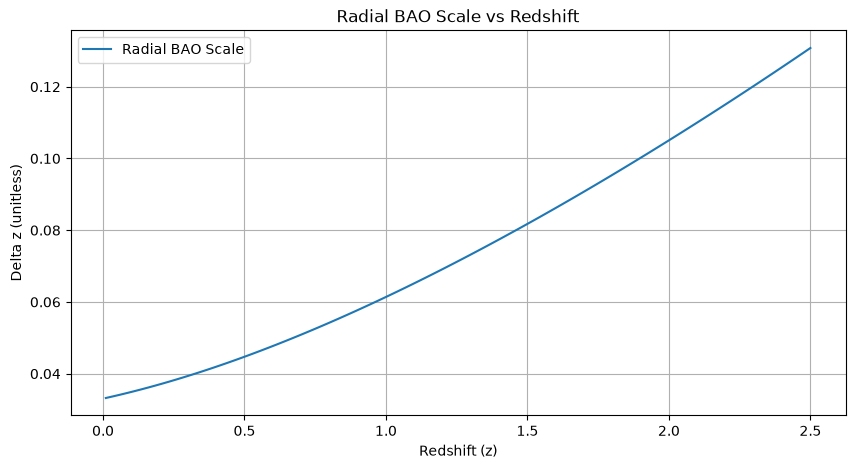

In [18]:
# restating the redshift range
z_values = np.linspace(0.01, 2.5, 100)

# plotting angular BAO scale
plt.figure(figsize=(10, 5))
# calculating angular BAO scale
theta_values = [delta_theta(z, hubble_const, omega_m, r_d) for z in z_values]
plt.plot(z_values, theta_values, label='Angular BAO Scale')
# adding labels and title
plt.xlabel('Redshift (z)')
plt.ylabel('Delta Theta (degrees)')
plt.title('Angular BAO Scale vs Redshift')
plt.grid(True)
plt.legend()
plt.show()


# plotting radial BAO scale
plt.figure(figsize=(10, 5))
# calculating radial BAO scale
delta_z_values = [delta_z(z, hubble_const, omega_m, r_d) for z in z_values]
plt.plot(z_values, delta_z_values, label='Radial BAO Scale')
# labeling plot
plt.xlabel('Redshift (z)')
plt.ylabel('Delta z (unitless)')
plt.title('Radial BAO Scale vs Redshift')
plt.grid(True)
plt.legend()
plt.show()

**Caption:** 

The first plot shows the angular BAO scale, Delta theta, against redshift using the reference cosmological parameters. The plot shows how the apparent angular separation of the BAO feature changes as the distance to the observed objects increases.

The second plot shows the radial BAO scale, Delta z, against redshift using the reference cosmological parameters. It shows the redshift separation corresponding to the sound horizon and how this separation changes with redshift.

### Plot 3: Toy r^2 xi(r)

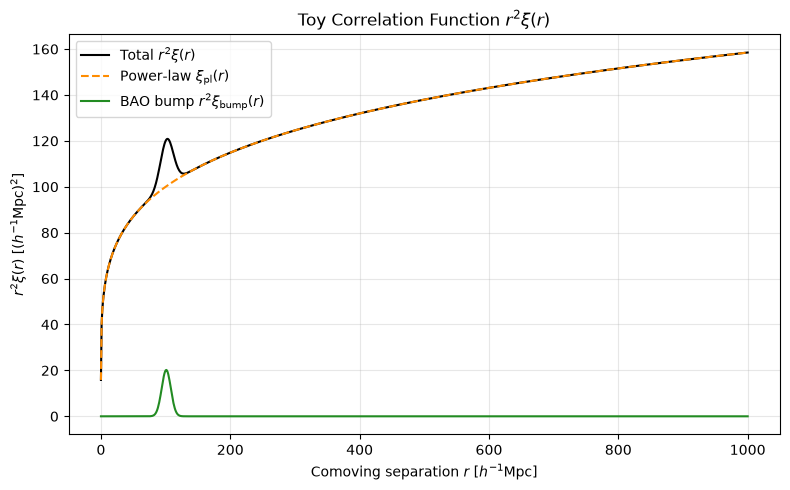

In [7]:
# Grid of r values up to r_max
r_vals = np.linspace(r_min, r_max, 1000)

# Evaluate model components using xi_model
xi_total = xi_model(r_vals, A, gamma, B, r_bao, sigma)
xi_smooth = xi_model(r_vals, A, gamma, 0, r_bao, sigma)
xi_bump = B * np.exp(-((r_vals - r_bao) ** 2) / (sigma**2))

# Plot r^2 * xi(r)
plt.figure(figsize=(8, 5))
plt.plot(r_vals, (r_vals**2) * xi_total, label=r'Total $r^2\xi(r)$', color='black')
plt.plot(r_vals, (r_vals**2) * xi_smooth, label=r'Power-law $\xi_{\mathrm{pl}}(r)$', color='darkorange', linestyle='--')
plt.plot(r_vals, (r_vals**2) * xi_bump, label=r'BAO bump $r^2\xi_{\mathrm{bump}}(r)$', color='forestgreen')
plt.xlabel(r'Comoving separation $r$ [$h^{-1}\mathrm{Mpc}$]')
plt.ylabel(r'$r^2 \xi(r)$ [$(h^{-1}\mathrm{Mpc})^2$]')
plt.title(r'Toy Correlation Function $r^2 \xi(r)$')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

**Caption:** This plot shows the toy correlation function weighted by $r^2$ to prevent the rapid decay of the smooth power-law background $\xi_{\mathrm{pl}}(r)$ from obscuring large-scale features. This $r^2$ scaling allows for the isolation of the sound horizon scale, making the localized Gaussian BAO bump $r^2\xi_{\mathrm{bump}}(r)$ visible as a distinct peak centered at $r_{\mathrm{bao}} = 100\,h^{-1}\mathrm{Mpc}$.

### Plot 4: P(k) with and without the bump, vs. the analytic approximation

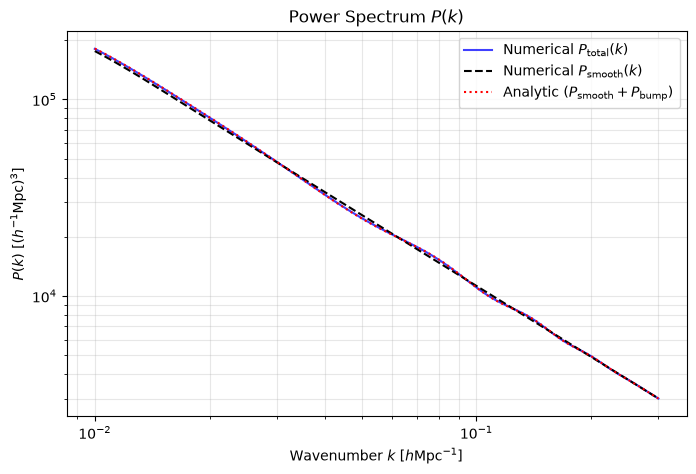

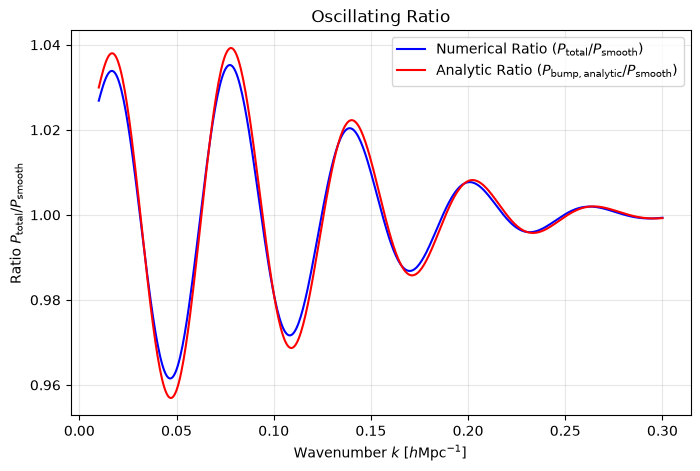

In [8]:
# Wavenumber range
k_vals = np.linspace(0.01,0.3, 500)

# Numerical power spectra using the defined function
P_total_num = P_ofk(xi_model, k_vals, A, gamma, B,
                    r_bao, sigma, r_taper, r_min, r_max)
P_smooth_num = P_ofk(xi_smooth_func, k_vals, A, gamma, B,
                     r_bao, sigma, r_taper, r_min, r_max)

# Analytic approximation of BAO bump
P_bump_analytic = (4.0 * np.pi * B * r_bao * np.sqrt(2.0 * np.pi) * sigma * np.sin(k_vals * r_bao) / k_vals) * np.exp(-(k_vals**2 * sigma**2) / 2.0)
P_total_analytic = P_smooth_num + P_bump_analytic

# Oscillating ratio
ratio_num = P_total_num / P_smooth_num
ratio_analytic = P_total_analytic / P_smooth_num

# Log-Log Power Spectrum Comparison
plt.figure(figsize=(8, 5))
plt.loglog(k_vals, P_total_num, label=r'Numerical $P_{\mathrm{total}}(k)$', color='blue', alpha=.75)
plt.loglog(k_vals, P_smooth_num, label=r'Numerical $P_{\mathrm{smooth}}(k)$', color='black', linestyle='--')
plt.loglog(k_vals, P_total_analytic, label=r'Analytic ($P_{\mathrm{smooth}} + P_{\mathrm{bump}}$)',
           color='red', linestyle=':')
plt.xlabel(r'Wavenumber $k$ [$h\mathrm{Mpc}^{-1}$]')
plt.ylabel(r'$P(k)$ [$(h^{-1}\mathrm{Mpc})^3$]')
plt.title(r'Power Spectrum $P(k)$')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()

# Plotting the Oscillating Ratio
plt.figure(figsize=(8, 5))
plt.plot(k_vals, ratio_num, label=r'Numerical Ratio ($P_{\mathrm{total}} / P_{\mathrm{smooth}}$)', color='blue')
plt.plot(k_vals, ratio_analytic, label=r'Analytic Ratio ($P_{\mathrm{bump, analytic}} / P_{\mathrm{smooth}}$)', color='red')
plt.xlabel(r'Wavenumber $k$ [$h\mathrm{Mpc}^{-1}$]')
plt.ylabel(r'Ratio $P_{\mathrm{total}} / P_{\mathrm{smooth}}$')
plt.title('Oscillating Ratio')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

**Caption:** The first plot is a log-log plot showing the power spectrum $P(k)$ as a function of wavenumber $k$, comparing the numerical power spectrum $P_{\mathrm{total}}(k)$, the smooth background spectrum $P_{\mathrm{smooth}}(k)$, and the analytic approximation $P_{\mathrm{smooth}} + P_{\mathrm{bump}}$. The power-law shape shows clustering, while the BAO feature introduces very small oscillations on the continuum.

The second plot shows the ratio $P_{\mathrm{total}}(k) / P_{\mathrm{smooth}}(k)$, shows the BAO wiggles by dividing out the smooth power-law background continuum. The oscillations demonstrate the Fourier transform of the spatial correlation peak at $r_{\mathrm{bao}} = 100\,h^{-1}\mathrm{Mpc}$, showing that the numerical transform and the analytic Fourier approximation are extremely close to eachother.

## Validation
*Run each check listed on your topic page; report what you found, including failures and what you did about them. The `check` helper below prints PASS or FAIL; use it or `np.isclose`/`assert`.*

In [19]:
def check(name, value, expected, rtol=1e-2, atol=0.0):
    """Print PASS/FAIL comparing value with expected (relative tolerance rtol)."""
    ok = np.isclose(value, expected, rtol=rtol, atol=atol)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, expected {expected:.6g}")
    return ok

# Example of use (replace with your own checks):
# check("name of check", your_function(args), value_from_topic_page, rtol=3e-3)

### Check 1: Table of D_M/r_d, D_H/r_d, D_V/r_d, Delta theta, Delta z at the listed redshifts

In [20]:
# updating check function with new tolerance
def check(name, value, expected, rtol=3e-3, atol=0.0):
    """Print PASS/FAIL comparing value with expected (relative tolerance rtol)."""
    ok = np.isclose(value, expected, rtol=rtol, atol=atol)
    print(f"{'PASS' if ok else 'FAIL'}  {name}: got {value:.6g}, expected {expected:.6g}")
    return ok

# setting redshifts
validation_redshifts = [0.38, 0.51, 0.61, 1.00, 2.33]

# expected values for each redshift
validation_DM = [10.43, 13.51, 15.72, 23.15, 39.24]
validation_DH = [24.62, 22.77, 21.42, 16.92, 8.64]
validation_DV = [10.06, 12.84, 14.78, 20.86, 31.41]
validation_theta = [5.49, 4.24, 3.65, 2.48, 1.46]
validation_delta_z = [0.0406, 0.0439, 0.0467, 0.0591, 0.1158]

# calculating and checking each value
for i, z in enumerate(validation_redshifts):

    # calculating distance ratios
    DM_ratio = D_M(z, hubble_const, omega_m) / r_d
    DH_ratio = D_H(z, hubble_const, omega_m) / r_d
    DV_ratio = D_V(z, hubble_const, omega_m) / r_d

    # calculating BAO scales
    theta = delta_theta(z, hubble_const, omega_m, r_d)
    redshift_separation = delta_z(z, hubble_const, omega_m, r_d)

    # checking calculated values against expected values
    print(f"\nRedshift z = {z}")

    check("D_M/r_d", DM_ratio, validation_DM[i])
    check("D_H/r_d", DH_ratio, validation_DH[i])
    check("D_V/r_d", DV_ratio, validation_DV[i])
    check("Delta theta", theta, validation_theta[i])
    check("Delta z", redshift_separation, validation_delta_z[i])


Redshift z = 0.38
FAIL  D_M/r_d: got 10.3302, expected 10.43
FAIL  D_H/r_d: got 24.1484, expected 24.62
FAIL  D_V/r_d: got 9.93034, expected 10.06
FAIL  Delta theta: got 5.54642, expected 5.49
FAIL  Delta z: got 0.0414106, expected 0.0406

Redshift z = 0.51
FAIL  D_M/r_d: got 13.3425, expected 13.51
FAIL  D_H/r_d: got 22.2144, expected 22.77
FAIL  D_V/r_d: got 12.6345, expected 12.84
FAIL  Delta theta: got 4.29423, expected 4.24
FAIL  Delta z: got 0.0450159, expected 0.0439

Redshift z = 0.61
FAIL  D_M/r_d: got 15.4939, expected 15.72
FAIL  D_H/r_d: got 20.8257, expected 21.42
FAIL  D_V/r_d: got 14.5016, expected 14.78
FAIL  Delta theta: got 3.69796, expected 3.65
FAIL  Delta z: got 0.0480177, expected 0.0467

Redshift z = 1.0
FAIL  D_M/r_d: got 22.687, expected 23.15
FAIL  D_H/r_d: got 16.2886, expected 16.92
FAIL  D_V/r_d: got 20.3148, expected 20.86
FAIL  Delta theta: got 2.52549, expected 2.48
FAIL  Delta z: got 0.0613926, expected 0.0591

Redshift z = 2.33
FAIL  D_M/r_d: got 38.0

### Check 2: D_V/r_d at z = 0.51 for three Omega_m

In [21]:
# setting matter density values
omega_values = [0.25, 0.30, 0.35]

# setting expected volume-averaged distance ratios
validation_DV = [13.24, 12.93, 12.63]

# checking volume-averaged distance for each matter density
for i, omega in enumerate(omega_values):

    # calculating volume-averaged distance ratio
    DV_ratio = D_V(0.51, hubble_const, omega) / r_d

    # checking calculated value
    check(f"D_V/r_d for omega_m = {omega}", DV_ratio, validation_DV[i])

PASS  D_V/r_d for omega_m = 0.25: got 13.2434, expected 13.24
PASS  D_V/r_d for omega_m = 0.3: got 12.926, expected 12.93
PASS  D_V/r_d for omega_m = 0.35: got 12.6345, expected 12.63


### Check 3: Analytic P_bump(k) vs. your transform

In [67]:
# Numerical bump by subtracting smooth spectrum from total spectrum
P_bump_num = P_total_num - P_smooth_num

# Evaluate across 4 target k values
k_targets = np.linspace(0.05, 0.2, 4)

for k_target in k_targets:
    idx = np.argmin(np.abs(k_vals - k_target))
    num_val = P_bump_num[idx]
    ana_val = P_bump_analytic[idx]
    print(f"P_bump numerical vs analytic at k={k_vals[idx]:.2f}",f"{num_val:.2f}", f"{ana_val:.2f}")

P_bump numerical vs analytic at k=0.05 -935.36 -1060.37
P_bump numerical vs analytic at k=0.10 -210.15 -210.10
P_bump numerical vs analytic at k=0.15 68.13 87.93
P_bump numerical vs analytic at k=0.20 37.58 38.95


At small $k$ ($0.05 \, h\mathrm{Mpc}^{-1}$), the numerical power spectrum differs from the analytic formula because the numerical transform includes a taper and finite integration bounds that eliminate large scale contributions. At intermediate $k$ ($0.10\, h\mathrm{Mpc}^{-1}$), the BAO peak lies within the untapered region, resulting in an extremely strong agreement near the sound horizon scale, as well as minor residuals at high $k$ ($0.15-20\, h\mathrm{Mpc}^{-1}$) from subtracting the two decaying functions.

## Discussion

Plots 1–3 are all related and show how the photon and baryon densities change as the universe expands. The photon density decreases faster than the baryon density because photons lose energy as the universe expands, while baryons mainly decrease in density as the universe gets larger. They physically show how photons have a much greater momentum density and strongly interact with baryons. It can also show how photons travel more freely during recombination as the universe cools and expands. Overall, the three plots show how the balance between photon and baryon densities changes over time and why baryons take slightly longer to stop being dragged by photons.The most important parameter in these Omega_m, since it changes the shape of the curve and affects how the distances evolve with redshift. Part 3 data can constrain the matter density and the expansion history of the universe by comparing observed BAO distances with the predicted curves.

Plots 4 and 5 show how the BAO standard ruler appears in the angular and radial directions as redshift increases. It physically shows how the angular BAO scale decreases as more distant objects appear smaller in the sky and how the redshift separation in the radial BAO scale changes with the expansion rate of the universe. The most important parameter is Omega_m, because it affects the expansion rate and distances at different redshifts. Part 3 data can constrain the matter density and expansion history of the universe by comparing predicted BAO scales at different redshifts. 

Plot 6 shows how multiplying the correlation function $\xi(r)$ by $r^2$ counteracts the decay of the smooth power-law background. This weighting shows the sound horizon scale, giving the localized BAO feature as a distinct peak centered at $r_{\mathrm{bao}} = 100\,h^{-1}\mathrm{Mpc}$. The most important parameters are $r_{\mathrm{vals}}$, $A$, $\gamma$, $B$, $r_{\mathrm{bao}}$, and $\sigma$. All of these formed the plot that you're seeing, and if any are changed it will change the normalization giving incorrect results.

Plot 7 transforms this spatial feature into Fourier space, where the real space peak creates oscillations on the power spectrum $P(k)$. Taking the ratio $P_{\mathrm{total}}(k) / P_{\mathrm{smooth}}(k)$ removes the  power-law continuum to reveal wiggles. This ratio confirms a strong match between the numerical transform and the analytic Fourier transform of a Gaussian BAO bump. The parameters that mattered most were all the ones described in plot 3 since that entire function was used inside the power spectrum. The ones exclusively for the power spectrum are $k$, $r_{\mathrm{taper}}$, $r_{\mathrm{min}}$, and $r_{\mathrm{max}}$. Where $k$ is the wavenumber, $r_{\mathrm{taper}}$ gave us a smoother for small $k$ creating a physical plot. $r_{\mathrm{min}}$, and $r_{\mathrm{max}}$ just gave us the bounds for the integral so that we could properly contain our values without balloning the graph to infinity.

## Extension section(s)

### Extension 1: Compute r_d yourself

In [16]:
# setting cosmological parameters
N_eff = 3.046 # effective number of massless neutrinos
w_b = 0.02237 # baryon density parameter
w_c = 0.1200 # cold dark matter density parameter
h = 0.6736 # dimensionless Hubble parameter
w_gamma = 2.4728e-5
z_drag = 1059.94 # drag epoch redshift
z_star = 1089.9 # recombination redshift


# updating function of Hubble parameter to include radiation density parameter
def H_z(z, hubble_const, omega_m):
    '''
    Calculates the Hubble parameter at a given redshift for a flat model with radiation density parameter
    Enter your value of z, returns in units of km/s/Mpc
    '''
    # setting omega_lambda for a flat universe
    omega_lambda = 1 - omega_m

    # radiation density parameter
    omega_r = w_gamma * (1 + 0.2271 * N_eff)

    # calculating Hubble parameter
    H = hubble_const * np.sqrt((omega_r * (1 + z)**4) + (omega_m * (1 + z)**3) + omega_lambda)

    return H

# calculating speed of sound 
def sound_speed(z):

    # calculating baryon-to-photon density ratio
    R = 3 * w_b / (4 * w_gamma * (1 + z))

    # calculating sound speed
    c_s = c / np.sqrt(3 * (1 + R))

    return c_s

# calculating sound horizon
def sound_horizon(z):

    # setting up the integral
    def integral(z_prime):

        # calculating sound speed and Hubble parameter
        c_s = sound_speed(z_prime)
        H = H_z(z_prime, hubble_const, omega_m)

        # returning integrand
        return c_s / H

    # integrating from redshift z to infinity
    distance = scipy.integrate.quad(integral, z, np.inf)[0]

    return distance

# calculating sound horizon at drag epoch
r_drag = sound_horizon(z_drag)

# calculating sound horizon at recombination
r_star = sound_horizon(z_star)

# printing results
print("\nSound horizon at drag epoch:", r_drag, "Mpc")
print("Sound horizon at recombination:", r_star, "Mpc")


Sound horizon at drag epoch: 168.48680685281494 Mpc
Sound horizon at recombination: 165.7685257789164 Mpc


During the recombination epoch, electrons and protons combined and formed neutral atoms, which allowed photons to travel freely. However, some photons still interacted with the leftover free electrons which transfered their momentum to the baryons. The drag epoch happens slightly later because these interactions became too weak to affect the baryons motion. It's also later because there are so many more photons than baryons which kept tugging on the baryons, since each baryon was being hit by so many photons.

In [16]:
# calculating the ratio
def ratio(z):
    photon_density = w_gamma * (1 + z)**4
    baryon_density = w_b * (1 + z)**3

    # comparing densities
    return (3 * baryon_density) / (4 * photon_density)

print("\nBaryon-to-photon density ratio at drag epoch:", ratio(z_drag))
print("Baryon-to-photon density ratio at recombination:", ratio(z_star))



Baryon-to-photon density ratio at drag epoch: 0.6395101352440263
Baryon-to-photon density ratio at recombination: 0.6219469088695548


### Extension 2: Bias in the measured peak position

In [44]:
# Setup of bins
r_bins = np.arange(30, 205, 5)
xi_true = xi_model(r_bins, A, gamma, B, r_bao, sigma)

# Noise level
amp_noise = .10 * B

# Define model functions
def Power_Law_Gaussian(r, A_fit, g_fit, B_fit, r_pk, sig_fit):
    return A_fit * (r / 100.0) ** (-g_fit) + B_fit * np.exp(-((r - r_pk) ** 2) / (2 * sig_fit ** 2))

def Gaussian(r, B_fit, r_pk, sig_fit):
    return B_fit * np.exp(-((r - r_pk) ** 2) / (2 * sig_fit ** 2))

def Gauss_Power_Poly(r, a0, a1, a2, B_fit, r_pk, sig_fit):
    poly = a0 + a1 * (r - 100.0) + a2 * (r - 100.0) ** 2
    bump = B_fit * np.exp(-((r - r_pk) ** 2) / (2 * sig_fit ** 2))
    return poly + bump

# Parameter bounds
bounds_a  = ([0, 0, 0, 30, 0.5], [1, 5, 1, 200, 50])
bounds_b1 = ([0, 30, 0.5], [1, 200, 50])
bounds_b2 = ([0, 30, 0.5], [1e5, 200, 50])
bounds_c  = ([-0.1, -0.01, -0.0001, 0, 30, 0.5], [0.1, 0.01, 0.0001, 1, 200, 50])

p0_a  = [A, gamma, B, r_bao, sigma]
p0_b1 = [B, r_bao, sigma]
p0_b2 = [B * 1e4, r_bao, sigma]
p0_c  = [0.001, 0.0, 0.0, B, r_bao, sigma]

# Simulation of all models
n_sims = 1000
peaks_a, peaks_b_xi, peaks_b_r2xi, peaks_c = [], [], [], []

for _ in range(n_sims):
    noise = rng.normal(0, amp_noise, len(r_bins))
    xi_obs = xi_true + noise
    
    # Model (a) Power_Law_Gaussian on xi(r)
    popt, _ = scipy.optimize.curve_fit(Power_Law_Gaussian, r_bins, xi_obs, p0=p0_a, bounds=bounds_a)
    peaks_a.append(popt[3])

    # Model (b1) Gaussian on xi(r)
    popt, _ = scipy.optimize.curve_fit(Gaussian, r_bins, xi_obs, p0=p0_b1, bounds=bounds_b1)
    peaks_b_xi.append(popt[1])

    # Model (b2) Gaussian on r^2 * xi(r)
    r2_xi_obs = (r_bins ** 2) * xi_obs
    popt, _ = scipy.optimize.curve_fit(Gaussian, r_bins, r2_xi_obs, p0=p0_b2, bounds=bounds_b2)
    peaks_b_r2xi.append(popt[1])

    # Model (c) Gauss_Power_Poly on xi(r)
    popt, _ = scipy.optimize.curve_fit(Gauss_Power_Poly, r_bins, xi_obs, p0=p0_c, bounds=bounds_c)
    peaks_c.append(popt[4])

print(f"(a) Power law + Gaussian:         r_peak = {np.mean(peaks_a):.2f} +/- {np.std(peaks_a):.2f} h^-1 Mpc")
print(f"(b1) Gaussian on xi(r):            r_peak = {np.mean(peaks_b_xi):.2f} +/- {np.std(peaks_b_xi):.2f} h^-1 Mpc")
print(f"(b2) Gaussian on r^2 * xi(r):      r_peak = {np.mean(peaks_b_r2xi):.2f} +/- {np.std(peaks_b_r2xi):.2f} h^-1 Mpc")
print(f"(c) Power law + Poly + Gaussian:  r_peak = {np.mean(peaks_c):.2f} +/- {np.std(peaks_c):.2f} h^-1 Mpc")

(a) Power law + Gaussian:         r_peak = 100.01 +/- 0.75 h^-1 Mpc
(b1) Gaussian on xi(r):            r_peak = 30.00 +/- 0.00 h^-1 Mpc
(b2) Gaussian on r^2 * xi(r):      r_peak = 124.62 +/- 0.94 h^-1 Mpc
(c) Power law + Poly + Gaussian:  r_peak = 132.26 +/- 0.17 h^-1 Mpc


**Model (a) Power Law + Gaussian:** Has almost a perfect peak recovery ($r_{\mathrm{peak}} = 100.01 \pm 0.75 \, h^{-1}\mathrm{Mpc}$) because modeling both the power-law background $\xi_{\mathrm{pl}}(r)$ and the Gaussian bump allows the fit to retrieve the true BAO peak position.

**Model (b1) Gaussian on $\xi(r)$:** Fails completely by collapsing to the lower bound ($r_{\mathrm{peak}} = 30.00 \pm 0.00 \, h^{-1}\mathrm{Mpc}$) because a single symmetric Gaussian without any background subtraction cannot get the steep, decaying baseline.

**Model (b2) Gaussian on $r^2 \xi(r)$:** Introduces a rightward bias ($r_{\mathrm{peak}} = 124.62 \pm 0.94 \, h^{-1}\mathrm{Mpc}$) because $r^2\xi(r)$ creates an increasing slope at larger distances, pushing the Gaussian peak toward higher background values at larger $r$.

**Model (c) Power Law + Poly + Gaussian:** Produces another rightward bias ($r_{\mathrm{peak}} = 132.26 \pm 0.17 \, h^{-1}\mathrm{Mpc}$) because polynomial parameter bounds are overly restrictive, preventing the quadratic baseline from  fitting the shape of the BAO position.

## Appendix A: AI usage
*Required even if you used none (say so). For each use: the tool, what you asked, what you used, how you verified it. If your use was substantial, add the Verification subsection described in Common Instructions section 6.*

### Verification (substantial use only)

**Niko Jamison** 

 

For each use of AI, I used ChatGPT. I asked it to explain topics like Fourier transforms and the power spectrum. I asked how we use Fourier transforms and the power spectrum in cases like Steps 4 and 5 of the Physics and Derivations part of the project. I used AI to help me understand the key concepts. 

 

Furthermore, I used AI to help me get started on Steps 4 and 5 of the Physics Derivations part. This helped me apply what I was just told to put into practical use and close the gap in my understanding. I also used AI to check my work on Steps 1-5. I verified the information from AI by using both the textbook from class and meeting with Professor Matini to help look over my Steps 1-3, help with my understanding of Fourier transforms and the power spectrum, and how I should get started on Steps 4 and 5, as well as what process to use and what the final answer should look like.

Logan Lajines
* **Tool used:** Google Gemini
* **What you asked:** 
  1. How to construct appropriate parameter boundsand initial guesses for scipy.optimize.curve_fit across the four models in Extension 2.
  2. How to properly apply LaTeX math syntax for figure labels, titles, and legend strings across Plots 3 and 4, as well as much of the syntax in markdown when using parameters(including here in the appendix)
  3. How to structure the inner function _calc_single_k(k_val) within $P(k)$ to iterate through scalar and vector $k$ inputs using scipy.integrate.quad.
* **What you used:** 
  1. The suggested lower and upper bound ranges for the power law amplitude $A$,  index $\gamma$, bump amplitude $B$, peak position $r_{\mathrm{bao}}$, width $\sigma$, and polynomial coefficients.
  2. LaTeX syntax for plot axis labels and title strings, along with similar syntax across my markdown cell answers.
  3. The inner helper function _calc_single_k inside $P(k)$ to handle array inputs and floating point values during integration.
* **How you verified it:** 
  1. Checked that curve_fit converged across all simulations without raising convergence warnings or boundary errors.
  2. Showed all plots in Jupyter to confirm that all titles, axis labels, and LaTeX math symbols formatted cleanly without syntax errors.
  3. Validated $P(k)$ output values against the carmen page to confirm numerical accuracy.

Evan Balwani
* **Tool used:** ChatGPT
* **What you asked:** 
  1. Checking the volume-averaged distance formuala
  2. Simplifying scipy.integrate.quad documentation to ensure how to add functions
  3. Checking Hubble parameter equation with radiation in extension 1
* **What you used:** 
  1. Cross checked my formula to ensure the variables and order is correct, and the overall formuala was correct
  2. Used this as a basis of how to add functions inside other functions when computing integrals
  3. Just cross checked my final formual to include radiation
* **How you verified it:** 
  1. The formula matched what I had
  2. It gave me the exact notes from the documentation and it worked when I followed its process
  3. It had given me a closer value to the true sound barrier

## Appendix B: References

**Niko Jamison** 

Alam, S., Aubert, M., Avila, S., Balland, C., Bautista, J. E., Bershady, M. A., Bizyaev, D., Blanton, M. R., Bolton, A. S., Bovy, J., Brinkmann, J., Brownstein, J. R., Burtin, E., Chabanier, S., Chapman, M. J., Choi, P. D., Chuang, C., Comparat, J., Cousinou, M., . . . Zheng, Z. (2021). Completed SDSS-IV extended Baryon Oscillation Spectroscopic Survey: Cosmological implications from two decades of spectroscopic surveys at the Apache Point Observatory. Physical Review. D/Physical Review. D., 103(8). https://doi.org/10.1103/physrevd.103.083533 

OpenAI. (2026). ChatGPT (GPT-6) [Large language model]. https://chatgpt.com/ 

Percival, W. J. (2017). Baryon acoustic oscillations: A cosmological ruler. Physics Today, 70(12), 32–38. https://doi.org/10.1063/pt.3.3789 

Ryden, Barbara Sue. Introduction to Cosmology Barbara Ryden. Pearson Pearson Education Limited, 2024. 

Shadab, A., Ata, M., Bailey, S., Beutler, F., Bizyaev, D., Blazek, J., Bolton, A., Brownstein, J., Burden, A., & Chuang, C.-H. (2017, March 28). The clustering of galaxies in the completed SDSS-III Baryon Oscillation Spectroscopic Survey: Cosmological analysis of the DR12 Galaxy sample. Oxford Academic. https://academic.oup.com/mnras/article/470/3/2617/3091741?login=false 


**Evan Balwani**
OpenAI. (2026). ChatGPT (GPT-6) [Large language model]. https://chatgpt.com/ 


## Changes since Part 2 (leave blank until Part 3)
*In Part 3, keep all of the material above and describe here what you changed and why.*